# **Homework 5**
Name: Maddox Guthrie \
Id: 12184185

# 1.1 Exercise 1: Solving Linear System of Equations

In [1]:
import numpy as np

In [2]:
def random_upper_matrix(n, low=-3, high=3):
    a = np.random.randint(low, high, size=(n, n))
    a = np.triu(a)
    for i in range(n):
        if a[i, i] == 0:
            a[i, i] = np.random.randint(1, high)
    return a

a) Suppose $A$ is a lower matrix. Write a function to solve the system $Ax = b$ using forward substitution

In [3]:
def forward_substitution(l, b):
    n = len(b)
    x = np.empty(shape=n, dtype=float)

    for i in range(n):
        x[i] = (b[i] - np.dot(x[:i], l[i, :i])) / l[i, i]
    return x

Now test your function to make sure it works properly.

In [4]:
L = np.flip(random_upper_matrix(5))
b = np.random.randint(1, 5, size=5)

x = forward_substitution(L, b)
x_np = np.linalg.solve(L, b)

np.allclose(x, x_np)

True

b) Suppose $A$ is an upper matrix. Write a function to solve the system $Ax = b$ using backward substitution

In [5]:
def backward_substitution(u, y):
    n = len(y)
    x = np.empty(shape=n, dtype=float)

    for i in range(n - 1, -1, -1):
        x[i] = (y[i] - np.dot(x[i+1:], u[i, i+1:])) / u[i, i]
    return x

Now test your function to make sure it works properly.

In [6]:
L = random_upper_matrix(5)
b = np.random.randint(1, 5, size=5)

x = backward_substitution(L, b)
x_np = np.linalg.solve(L, b)

np.allclose(x, x_np)

True

# 1.2 Exercise 2: LU Decomposition
Write a Python function that takes the input as an $n \times n$ matrix and return the lower and upper matrices in the LU decomposition form. Students need to implement the algorithm from the scratch as we did in class.

In [7]:
def lu_decomposition(A):
    m, n = A.shape
    if m != n:
        raise ValueError("THe matrix must be square!")

    M = A.copy().astype(float)
    L = np.eye(n)
    U = np.zeros((n, n))

    for i in range(n):
        U[i, i:] = M[i, i:]
        L[i:, i] = M[i:, i] / M[i, i]
        if i < n-1:
            M[i+1:, i+1:] = M[i+1:, i+1:] - np.outer(L[i+1:, i], U[i, i+1:])

    return L, U

Test your function by using `random_upper_matrix` above.

In [8]:
a = random_upper_matrix(5)
b = random_upper_matrix(5)
c = a.T @ b
l, u = lu_decomposition(c)

In [9]:
# check if the decomposition is correct
assert np.allclose(l @ u, c), "LU decomposition is incorrect"

# 1.3 Exercise 3: Computational Complexity of LU Decomposition
Conduct an experiment to analyze the computational complexity of LU decomposition by visualizing the relationship between matrix size and execution time using a log-log plot.

- **Generate Random Matrices:** Create square matrices $A$ with sizes ranging from $n = 1000$ to $n = 5000$ in increments of 100.
- **Measure Execution Time:** Use `scipy.linalg.lu()` function from Scipy to compute the LU decomposition for each matrix, recording the execution time.
- **Collect Data:** Store each matrix size $n$ and its corresponding computation time for analysis.
- **Log-Log Plot:** Plot the graph to visualize the scaling behavior of execution time with respect to matrix size.
- **Analyze Complexity:** Determine the slope of the log-log plot to assess the computational complexity of LU decomposition. Compare the observed trend with the expected $𝑂(n^3)$ complexity and discuss any deviations or insights from the experiment.

In [10]:
import matplotlib.pyplot as plt
import time
import numpy as np
import scipy

In [11]:
start_size = 1000
end_size = 5000
step_size = 100

In [12]:
sizes = range(start_size, end_size + 1, step_size)
times = []

In [13]:
scipy.linalg.lu(np.random.rand(1000, 1000)) # Pre-initialize BLAS
for n in sizes:
    A = np.random.randint(1, 10, size=(n, n))

    start = time.time()
    scipy.linalg.lu(A)
    end = time.time()

    times.append(end - start)

In [14]:
sizes = np.arange(start_size, end_size + 1, step_size)

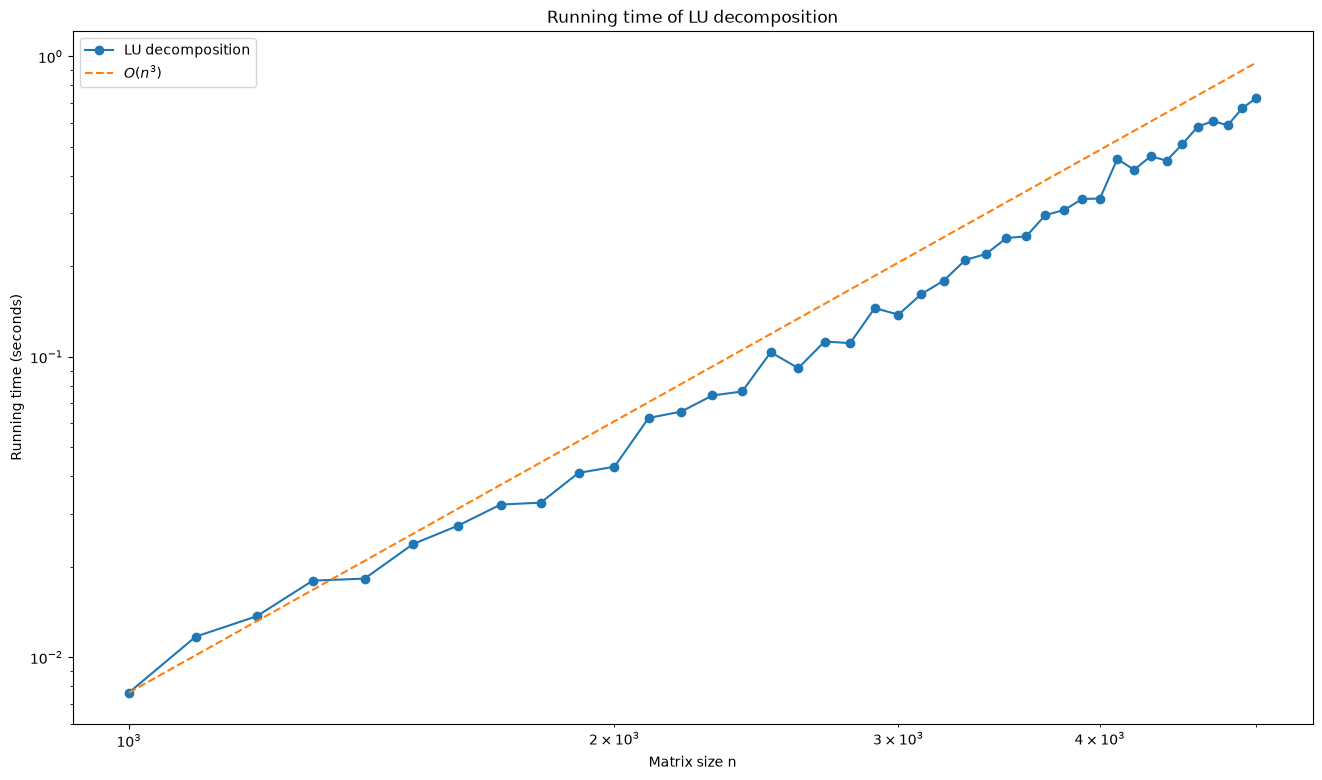

In [15]:
fig, ax = plt.subplots(figsize=(16, 9))

ax.loglog(sizes, times, "o-", label="LU decomposition")
ax.loglog(sizes, times[0] * (sizes / sizes[0])**3, "--", label=r"$O(n^3)$")

ax.set_title("Running time of LU decomposition")
ax.set_xlabel("Matrix size n")
ax.set_ylabel("Running time (seconds)")
ax.legend()

plt.show()

In [16]:
slope, intercept = np.polyfit(np.log(sizes), np.log(times), 1)
print(f"slope = {slope:.2f}")

slope = 2.79


In [17]:
slope, intercept = np.polyfit(np.log(sizes), np.log(times[0] * (sizes / sizes[0])**3), 1)
print(f"slope = {slope:.2f}")

slope = 3.00


The log-log plot of running time vs. matrix size is close to a straight line. The fitted slope is about $2.79$ (varies), which is close to the expected $3$ since LU takes about $\frac{2}{3}n^3$ operations. The data follows the $O(n^3)$ reference line but drifts a bit below it at larger $n$, which is why the slope is under $3$. This is probably because SciPy's multithreaded BLAS runs more efficiently on larger matrices, while at smaller $n$ memory access and overhead matter more. Other programs running on the computer also add some noise. I ran the function once before timing so start-up overhead didn't affect the first point. Overall the results are consistent with $O(n^3)$ complexity.